# EDA — Datos abiertos de MiBici

**TC5044 Operaciones de aprendizaje automático · Fase 1 · Equipo 15**

Problema de ML: *predecir la demanda de retiros de bicicleta por estación y franja horaria*, para apoyar las decisiones de rebalanceo de la flota.

Este notebook es **narrativa, no implementación**. Toda la lógica vive en `tc5044_mlops/eda.py` y `tc5044_mlops/features.py`, versionados en Git y reutilizables desde los scripts del pipeline. El notebook solo importa, llama y comenta — que es lo que pide el punto 5 del entregable sobre refactorización.

**Prerrequisito:** haber corrido el pipeline de datos.

```bash
dvc repro                    # descargar -> consolidar -> limpiar
python scripts/versionar_mlflow.py
```

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from tc5044_mlops import eda, features

eda.estilo()
pd.set_option("display.width", 120)

2026-10-25 19:49:44.938 | INFO     | tc5044_mlops.config:<module>:11 - PROJ_ROOT path is: /home/jhonatan0925/mlops/tc5044-mlops


## 1. Carga del dataset versionado

Se carga la versión **v2-limpio**, registrada en MLflow. Por defecto se excluyen los viajes marcados como inválidos — duración fuera del rango de 1 a 1440 minutos — pero la bandera `viaje_valido` sigue en el archivo, de modo que el conteo original es recuperable y la exclusión es auditable.

In [2]:
df = eda.cargar("../data/processed/mibici_viajes.parquet")
df.head()

7,177,674 viajes válidos de 7,404,041 (96.94 %)


,viaje_id,usuario_id,genero,anio_nacimiento,inicio_viaje,fin_viaje,origen_id,destino_id,periodo,archivo_origen,...,destino_estacion_nombre,destino_latitud,destino_longitud,estacion_catalogada,hora,dia_semana,es_fin_semana,mes,fecha,viaje_redondo
0,37162342,601273,M,1982,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395,2025-01,datos_abiertos_2025_01.csv,...,(GDL-276) Francisco de Quevedo / Miguel Lerdo,20.671045,-103.381349,True,0,2,False,1,2025-01-01,False
1,37162343,1571524,M,2003,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260,2025-01,datos_abiertos_2025_01.csv,...,(GDL-187) Av. 16 de Septiembre / C. Priscilia,20.672639,-103.347155,True,0,2,False,1,2025-01-01,False
2,37162344,1435200,F,1984,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260,2025-01,datos_abiertos_2025_01.csv,...,(GDL-187) Av. 16 de Septiembre / C. Priscilia,20.672639,-103.347155,True,0,2,False,1,2025-01-01,False
3,37162345,126327,M,1988,2025-01-01 00:07:47,2025-01-01 00:17:42,190,11,2025-01,datos_abiertos_2025_01.csv,...,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,True,0,2,False,1,2025-01-01,False
4,37162346,416121,M,1994,2025-01-01 00:08:52,2025-01-01 00:18:10,273,8,2025-01,datos_abiertos_2025_01.csv,...,(GDL-006) C. Venustiano Carranza /C. Reforma,20.680717,-103.344415,True,0,2,False,1,2025-01-01,False


In [3]:
perfil = eda.perfil_descriptivo(df)
perfil

,Indicador,Valor
0,Viajes,"7,177,674"
1,Periodo,2025-01 a 2026-08
2,Usuarios únicos,"39,427"
3,Estaciones activas,472
4,Duración mediana (min),9.80
5,Duración media (min),11.46
6,Duración P95 (min),24.60
7,Viajes redondos,3.45 %
8,Viajes en fin de semana,21.11 %
9,Edad mediana,32


## 2. Estructura temporal de la demanda

Esta es la figura que decide si el problema es resoluble. Si el perfil horario fuera plano, la hora no aportaría información y habría que buscar otras variables.

figura -> ../reports/figures/eda_perfil_horario.png


PosixPath('../reports/figures/eda_perfil_horario.png')

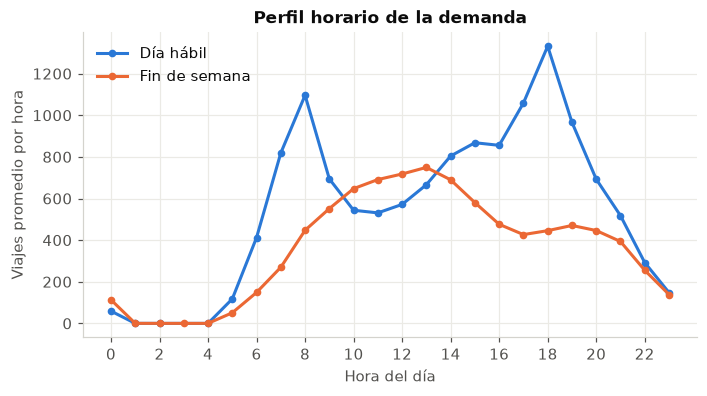

In [4]:
fig = eda.fig_demanda_horaria(df)
eda.guardar(fig, "eda_perfil_horario", Path("../reports/figures"))

**Lectura.** El día hábil tiene un perfil bimodal con picos cerca de las 8 y las 18 horas: es un patrón de conmutación casa–trabajo. El fin de semana el perfil es unimodal y se desplaza al mediodía, con un volumen máximo claramente menor. La hora del día y el tipo de día son, por tanto, predictores de primer orden, y justifican codificarlos de forma cíclica (seno/coseno) en lugar de como enteros.

figura -> ../reports/figures/eda_heatmap_dia_hora.png


PosixPath('../reports/figures/eda_heatmap_dia_hora.png')

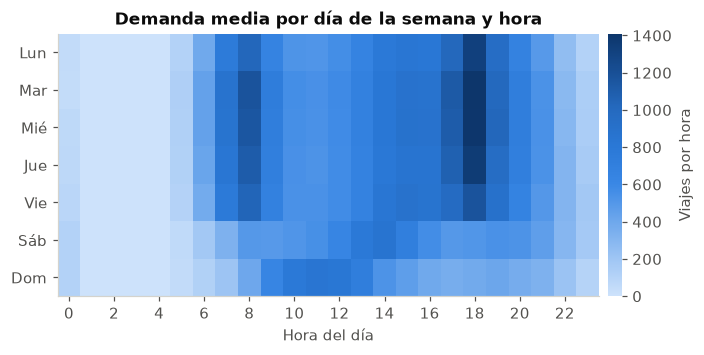

In [5]:
fig = eda.fig_heatmap_hora_dia(df)
eda.guardar(fig, "eda_heatmap_dia_hora", Path("../reports/figures"))

figura -> ../reports/figures/eda_serie_mensual.png


PosixPath('../reports/figures/eda_serie_mensual.png')

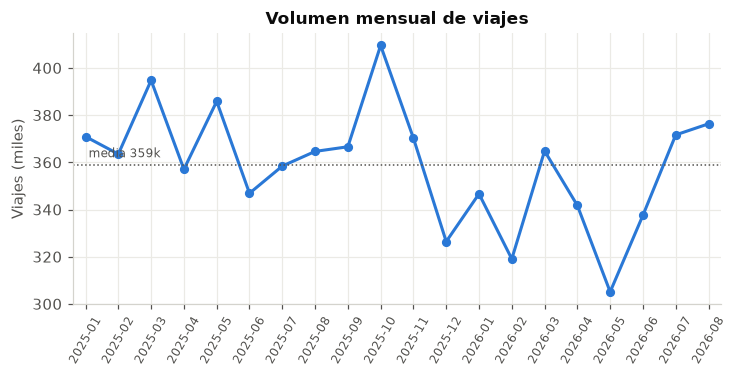

In [6]:
fig = eda.fig_serie_mensual(df)
eda.guardar(fig, "eda_serie_mensual", Path("../reports/figures"))

**Lectura.** El volumen mensual es notablemente estable en el periodo analizado, sin tendencia marcada ni saltos superiores al 35 %. Es una buena noticia para el modelado y un problema para la Fase 3: no hay *drift* natural que detectar en esta ventana. Se documenta aquí porque condiciona la estrategia de monitoreo que se definirá más adelante.

## 3. Distribución de la duración y concentración espacial

figura -> ../reports/figures/eda_duracion.png


PosixPath('../reports/figures/eda_duracion.png')

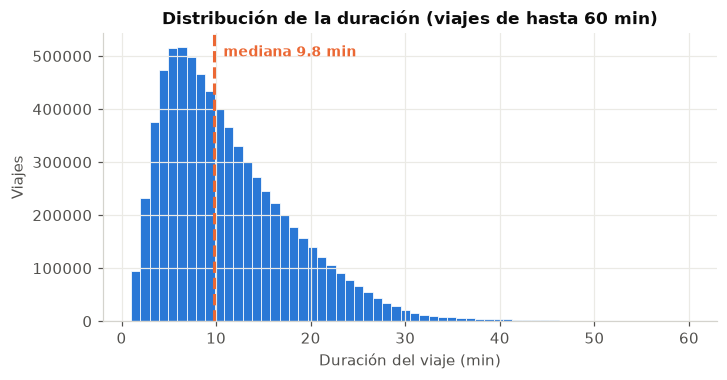

In [7]:
fig = eda.fig_distribucion_duracion(df)
eda.guardar(fig, "eda_duracion", Path("../reports/figures"))

figura -> ../reports/figures/eda_top_estaciones.png


PosixPath('../reports/figures/eda_top_estaciones.png')

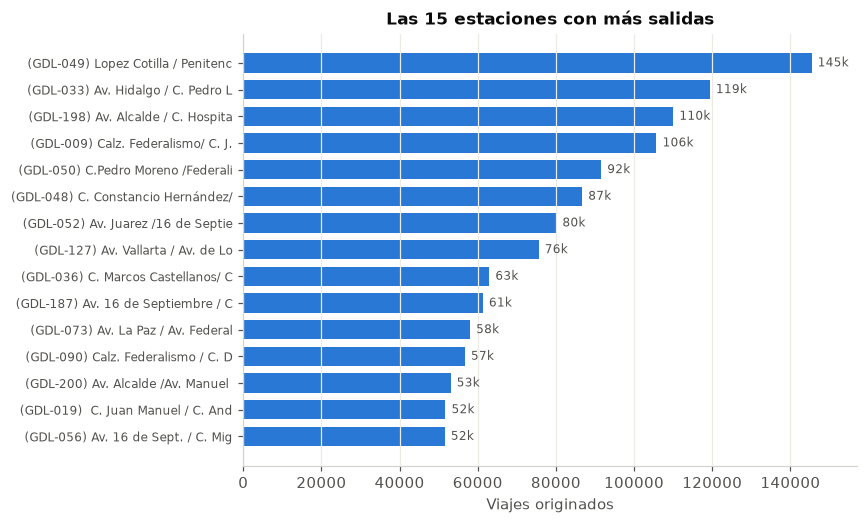

In [8]:
fig = eda.fig_top_estaciones(df, n=15)
eda.guardar(fig, "eda_top_estaciones", Path("../reports/figures"))

In [9]:
# Concentración: qué porcentaje de la demanda explican las N estaciones más activas
salidas = df["origen_id"].value_counts()
acum = salidas.cumsum() / salidas.sum()
for n in (10, 25, 50, 100):
    print(f"las {n:>3} estaciones más activas concentran {100*acum.iloc[n-1]:.1f} % de las salidas")

las  10 estaciones más activas concentran 13.1 % de las salidas
las  25 estaciones más activas concentran 23.4 % de las salidas
las  50 estaciones más activas concentran 36.8 % de las salidas
las 100 estaciones más activas concentran 57.2 % de las salidas


**Lectura.** La demanda está concentrada en una fracción de las estaciones. Esto respalda la decisión de acotar la tabla de modelado a las estaciones más activas: se conserva el grueso de la señal con una fracción del costo computacional, y las estaciones de baja demanda —donde el conteo horario es casi siempre cero— se tratarían mejor con un modelo distinto.

## 4. Composición demográfica

No alimenta el modelo de demanda, pero es relevante para la propuesta de valor y para la discusión de equidad del servicio.

figura -> ../reports/figures/eda_genero_edad.png


PosixPath('../reports/figures/eda_genero_edad.png')

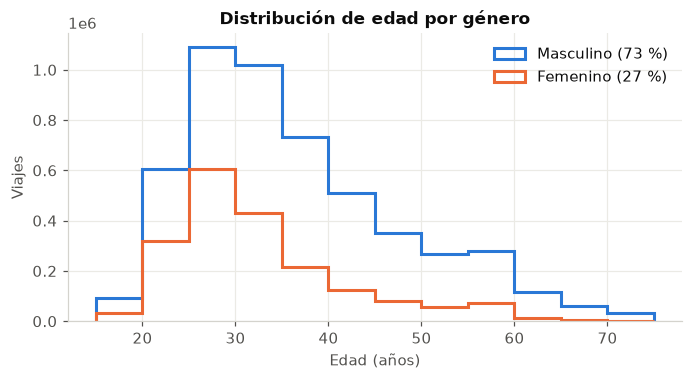

In [10]:
fig = eda.fig_genero_edad(df)
eda.guardar(fig, "eda_genero_edad", Path("../reports/figures"))

## 5. Preprocesamiento: de viajes a tabla de modelado

El dataset es un registro por viaje; el problema exige un registro por estación y hora. La transformación incluye las horas sin viajes con demanda cero: una estación sin retiros a las 3 de la madrugada es una observación válida, no un dato faltante, y omitirla sesgaría el modelo hacia arriba.

In [11]:
tabla = features.tabla_modelado(df, top_estaciones=50)
print(tabla.shape)
tabla.head()

50 estaciones, 2,642,708 viajes
rejilla completa: 729,600 filas (30.2 % en cero)


(729600, 19)


,origen_id,fecha_hora,demanda,hora,dia_semana,es_fin_semana,mes,dia_del_anio,hora_sin,hora_cos,dia_sin,dia_cos,demanda_lag_1h,demanda_lag_2h,demanda_lag_24h,demanda_lag_168h,demanda_media_3h,demanda_media_24h,demanda_media_168h
0,4,2025-01-01 00:00:00,0,0,2,0,1,1,0.000000,1.000000,0.974928,-0.222521,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4,2025-01-01 01:00:00,0,1,2,0,1,1,0.258819,0.965926,0.974928,-0.222521,0.0,NaN,NaN,NaN,0.0,0.0,0.0
2,4,2025-01-01 02:00:00,0,2,2,0,1,1,0.500000,0.866025,0.974928,-0.222521,0.0,0.0,NaN,NaN,0.0,0.0,0.0
3,4,2025-01-01 03:00:00,0,3,2,0,1,1,0.707107,0.707107,0.974928,-0.222521,0.0,0.0,NaN,NaN,0.0,0.0,0.0
4,4,2025-01-01 04:00:00,0,4,2,0,1,1,0.866025,0.500000,0.974928,-0.222521,0.0,0.0,NaN,NaN,0.0,0.0,0.0


In [12]:
tabla.describe().T

,count,mean,min,25%,50%,75%,max,std
origen_id,729600.0,102.62,4.0,36.0,63.5,170.0,333.0,87.833514
fecha_hora,729600,2025-10-31 23:30:00,2025-01-01 00:00:00,2025-06-01 23:45:00,2025-10-31 23:30:00,2026-04-01 23:15:00,2026-08-31 23:00:00,NaN
demanda,729600.0,3.622133,0.0,0.0,2.0,5.0,205.0,4.616342
hora,729600.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922191
dia_semana,729600.0,3.003289,0.0,1.0,3.0,5.0,6.0,1.999999
es_fin_semana,729600.0,0.286184,0.0,0.0,0.0,1.0,1.0,0.451977
mes,729600.0,5.726974,1.0,3.0,6.0,8.0,12.0,3.194024
dia_del_anio,729600.0,158.620066,1.0,76.75,152.5,228.25,365.0,97.59256
hora_sin,729600.0,0.0,-1.0,-0.707107,0.0,0.707107,1.0,0.707107
hora_cos,729600.0,0.0,-1.0,-0.707107,-0.0,0.707107,1.0,0.707107


### Partición cronológica

La partición es por fecha, nunca aleatoria. Un `train_test_split` al azar sobre una serie de tiempo entrena con el futuro y evalúa con el pasado; produce métricas infladas que no se reproducen en producción.

Ajusta los cortes al rango real de tu descarga.

In [13]:
tr, va, te = features.particion_temporal(tabla, corte_val="2026-05-01", corte_test="2026-07-01")

train :   582,000 filas  2025-01-01 a 2026-04-30
val   :    73,200 filas  2026-05-01 a 2026-06-30
test  :    74,400 filas  2026-07-01 a 2026-08-31


In [14]:
salida = Path("../data/processed/mibici_demanda_horaria.parquet")
tabla.to_parquet(salida, index=False, compression="zstd")
print(f"{len(tabla):,} filas -> {salida}")

729,600 filas -> ../data/processed/mibici_demanda_horaria.parquet


## 6. Registro de esta versión en MLflow

La tabla de modelado es una tercera versión del dataset y se registra como tal, con su esquema, su perfil y su digest.

In [15]:
import mlflow

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("mibici-versionado-datasets")

with mlflow.start_run(run_name="mibici-v3-demanda-horaria"):
    mlflow.set_tags({"etapa": "modelado", "granularidad": "estacion-hora"})
    mlflow.log_input(
        mlflow.data.from_pandas(tabla, source=str(salida), name="mibici-v3-demanda-horaria"),
        context="modelado",
    )
    mlflow.log_params({
        "top_estaciones": 50,
        "granularidad": "1h",
        "lags_horas": str(features.LAGS_HORAS),
        "ventanas_moviles": str(features.VENTANAS_MOVILES),
        "corte_val": "2026-05-01",
        "corte_test": "2026-07-01",
    })
    mlflow.log_metrics({
        "filas": len(tabla),
        "estaciones": tabla.origen_id.nunique(),
        "pct_horas_sin_demanda": round(100 * (tabla.demanda == 0).mean(), 3),
        "demanda_media": round(float(tabla.demanda.mean()), 3),
        "demanda_max": int(tabla.demanda.max()),
    })
    for f in sorted(Path("../reports/figures").glob("eda_*.png")):
        mlflow.log_artifact(str(f), artifact_path="figuras_eda")

print("Registrado. Captura la UI de MLflow como evidencia del punto 4.")

/home/jhonatan0925/mlops/tc5044-mlops/.venv/lib/python3.11/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


/home/jhonatan0925/mlops/tc5044-mlops/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run mibici-v3-demanda-horaria at: http://localhost:5000/#/experiments/2/runs/1fe8dac577d34d56bb231f1bd749114b
🧪 View experiment at: http://localhost:5000/#/experiments/2
Registrado. Captura la UI de MLflow como evidencia del punto 4.


## 7. Hallazgos

1. **La demanda tiene estructura horaria fuerte y distinta entre día hábil y fin de semana.** El problema es resoluble con variables de calendario y rezagos, sin necesidad de fuentes externas.
2. **La demanda está concentrada espacialmente**, lo que permite acotar la tabla de modelado sin perder señal.
3. **El volumen mensual es estable en la ventana analizada**, por lo que la Fase 3 requerirá una estrategia explícita de simulación de *drift*.
4. **La calidad de la fuente es alta**: tras la limpieza, más del 96 % de los viajes son válidos, y los defectos encontrados son acotados y documentados.
5. **El catálogo de estaciones es una foto del estado presente**, no un histórico, por lo que estaciones retiradas no cruzan contra los viajes antiguos.